In [1]:
import os, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

TRAIN_PATH = "train.csv"
TEST_PATH = "test.csv"
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

SEED = 42
TARGET = "Credit_Score"
CLASSES = ["Poor", "Standard", "Good"]
CLASS_MAP = {c: i for i, c in enumerate(CLASSES)}
MONTHS = ["January", "February", "March", "April", "May", "June", "July", "August",
          "September", "October", "November", "December"]

In [2]:
train = pd.read_csv(TRAIN_PATH, low_memory=False)
test = pd.read_csv(TEST_PATH, low_memory=False)


shape_table = pd.DataFrame(
    {"Rows": [train.shape[0], test.shape[0]],
     "Columns": [train.shape[1], test.shape[1]]},
    index=["train.csv", "test.csv"],
)
display(shape_table)

,Rows,Columns
train.csv,100000,28
test.csv,50000,27


In [3]:
print(train.head())

       ID Customer_ID     Month           Name   Age          SSN Occupation Annual_Income  Monthly_Inhand_Salary  Num_Bank_Accounts  Num_Credit_Card  Interest_Rate Num_of_Loan  \
0  0x1602   CUS_0xd40   January  Aaron Maashoh    23  821-00-0265  Scientist      19114.12            1824.843333                  3                4              3           4   
1  0x1603   CUS_0xd40  February  Aaron Maashoh    23  821-00-0265  Scientist      19114.12                    NaN                  3                4              3           4   
2  0x1604   CUS_0xd40     March  Aaron Maashoh  -500  821-00-0265  Scientist      19114.12                    NaN                  3                4              3           4   
3  0x1605   CUS_0xd40     April  Aaron Maashoh    23  821-00-0265  Scientist      19114.12                    NaN                  3                4              3           4   
4  0x1606   CUS_0xd40       May  Aaron Maashoh    23  821-00-0265  Scientist      19114.12          

In [4]:
print(test.head())

       ID Customer_ID      Month             Name  Age          SSN Occupation Annual_Income  Monthly_Inhand_Salary  Num_Bank_Accounts  Num_Credit_Card  Interest_Rate Num_of_Loan  \
0  0x160a   CUS_0xd40  September    Aaron Maashoh   23  821-00-0265  Scientist      19114.12            1824.843333                  3                4              3           4   
1  0x160b   CUS_0xd40    October    Aaron Maashoh   24  821-00-0265  Scientist      19114.12            1824.843333                  3                4              3           4   
2  0x160c   CUS_0xd40   November    Aaron Maashoh   24  821-00-0265  Scientist      19114.12            1824.843333                  3                4              3           4   
3  0x160d   CUS_0xd40   December    Aaron Maashoh  24_  821-00-0265  Scientist      19114.12                    NaN                  3                4              3           4   
4  0x1616  CUS_0x21b1  September  Rick Rothackerj   28  004-07-5839    _______      34847.

In [5]:
print("Dtypes (train):")
print(train.dtypes.value_counts().to_string())

miss = train.isna().sum()
print("\nMissing values (train):")
display(miss[miss > 0].to_frame("Missing").assign(Pct=lambda d: (d.Missing / len(train) * 100).round(2)))

print("\nTarget distribution (train):")
display(train[TARGET].value_counts(normalize=True).round(3).to_frame("Share"))

print(f"Customers: train={train.Customer_ID.nunique()}  test={test.Customer_ID.nunique()}  "
      f"shared={len(set(train.Customer_ID) & set(test.Customer_ID))}")
print(f"Months: train={train.Month.unique().tolist()}")
print(f"        test ={test.Month.unique().tolist()}")

Dtypes (train):
str        20
float64     4
int64       4

Missing values (train):


,Missing,Pct
Name,9985,9.98
Monthly_Inhand_Salary,15002,15.00
Type_of_Loan,11408,11.41
Num_of_Delayed_Payment,7002,7.00
Num_Credit_Inquiries,1965,1.96
Credit_History_Age,9030,9.03
Amount_invested_monthly,4479,4.48
Monthly_Balance,1200,1.20



Target distribution (train):


,Share
Credit_Score,
Standard,0.532
Poor,0.290
Good,0.178


Customers: train=12500  test=12500  shared=12500
Months: train=['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']
        test =['September', 'October', 'November', 'December']


In [6]:
junk = pd.Series({
    "Occupation '_______'": (train.Occupation == "_______").sum(),
    "SSN '#F%$D@*&8'": (train.SSN == "#F%$D@*&8").sum(),
    "Credit_Mix '_'": (train.Credit_Mix == "_").sum(),
    "Payment_Behaviour '!@9#%8'": (train.Payment_Behaviour == "!@9#%8").sum(),
    "Amount_invested_monthly '__10000__'": (train.Amount_invested_monthly.astype(str) == "__10000__").sum(),
    "Changed_Credit_Limit '_'": (train.Changed_Credit_Limit.astype(str) == "_").sum(),
    "Payment_of_Min_Amount 'NM'": (train.Payment_of_Min_Amount == "NM").sum(),
}, name="Rows affected")
display(junk.to_frame())

n_changing = int((train.groupby("Customer_ID")[TARGET].nunique() > 1).sum())
print(f"Customers whose Credit_Score changes between months: {n_changing} of {train.Customer_ID.nunique()}")

,Rows affected
Occupation '_______',7062
SSN '#F%$D@*&8',5572
Credit_Mix '_',20195
Payment_Behaviour '!@9#%8',7600
Amount_invested_monthly '__10000__',4305
Changed_Credit_Limit '_',2091
Payment_of_Min_Amount 'NM',12007


Customers whose Credit_Score changes between months: 7292 of 12500


In [7]:
def to_number(s):

    return pd.to_numeric(s.astype(str).str.strip().str.replace("_", "", regex=False)
                         .replace({"": np.nan, "nan": np.nan, "None": np.nan}), errors="coerce")

def parse_history_age(s):

    m = s.astype(str).str.extract(r"(\d+)\s*Years?\s*and\s*(\d+)\s*Months?").astype(float)
    return m[0] * 12 + m[1]

In [8]:

train_part, test_part = train.copy(), test.copy()
train_part["_is_train"], test_part["_is_train"] = 1, 0
test_part[TARGET] = np.nan
df = pd.concat([train_part, test_part], ignore_index=True)


df["Month_Num"] = df["Month"].map({m: i + 1 for i, m in enumerate(MONTHS)})
df["_row_id"] = df["ID"]
cols_to_drop = ["ID", "Name", "SSN"]
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
print("Dropped:", cols_to_drop, "->", df.shape)

Dropped: ['ID', 'Name', 'SSN'] -> (150000, 28)


In [9]:

cols_to_clean = ["Age", "Annual_Income", "Num_of_Loan", "Num_of_Delayed_Payment", "Changed_Credit_Limit",
                 "Outstanding_Debt", "Amount_invested_monthly", "Monthly_Balance", "Num_Credit_Inquiries"]
for col in cols_to_clean:
    df[col] = to_number(df[col])


df["Credit_History_Months"] = parse_history_age(df["Credit_History_Age"])
df = df.drop(columns="Credit_History_Age")

df.loc[df["Amount_invested_monthly"] >= 10000, "Amount_invested_monthly"] = np.nan
df.loc[df["Monthly_Balance"].abs() > 1e6, "Monthly_Balance"] = np.nan

In [ ]:

bounds = {"Age": (14, 100), "Annual_Income": (0, 200_000), "Num_Bank_Accounts": (0, 20),
          "Num_Credit_Card": (0, 20), "Interest_Rate": (0, 40), "Num_of_Loan": (0, 10),
          "Num_of_Delayed_Payment": (0, 30), "Num_Credit_Inquiries": (0, 30),
          "Total_EMI_per_month": (0, 1500)}
anomaly_rows = []
for col, (lo, hi) in bounds.items():
    bad = ~df[col].between(lo, hi) & df[col].notna()
    df.loc[bad, col] = np.nan
    anomaly_rows.append({"Column": col, "Valid range": f"[{lo}, {hi}]", "Anomalies -> NaN": int(bad.sum())})
display(pd.DataFrame(anomaly_rows))

,Column,Valid range,Anomalies -> NaN
0,Age,"[14, 100]",4177
1,Annual_Income,"[0, 200000]",1500
2,Num_Bank_Accounts,"[0, 20]",1986
3,Num_Credit_Card,"[0, 20]",3439
4,Interest_Rate,"[0, 40]",3000
5,Num_of_Loan,"[0, 10]",6580
6,Num_of_Delayed_Payment,"[0, 30]",2062
7,Num_Credit_Inquiries,"[0, 30]",2493
8,Total_EMI_per_month,"[0, 1500]",4890


In [ ]:

df["Occupation"] = df["Occupation"].replace("_______", np.nan)
df["Credit_Mix"] = df["Credit_Mix"].replace("_", np.nan)
df["Payment_Behaviour"] = df["Payment_Behaviour"].replace("!@9#%8", np.nan)
df["Payment_of_Min_Amount"] = df["Payment_of_Min_Amount"].replace("NM", np.nan)


df = df.sort_values(["Customer_ID", "Month_Num"]).reset_index(drop=True)

const_cols = ["Age", "Occupation", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts",
              "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", "Type_of_Loan", "Outstanding_Debt",
              "Total_EMI_per_month", "Credit_Mix", "Payment_of_Min_Amount", "Credit_History_Months",
              "Payment_Behaviour"]
before = int(df[const_cols].isna().sum().sum())
df[const_cols] = df.groupby("Customer_ID", sort=False)[const_cols].ffill()
df[const_cols] = df.groupby("Customer_ID", sort=False)[const_cols].bfill()
print(f"ffill + bfill within customer: {before} -> {int(df[const_cols].isna().sum().sum())} missing cells")

ffill + bfill within customer: 148584 -> 17112 missing cells


In [ ]:

var_cols = ["Delay_from_due_date", "Num_of_Delayed_Payment", "Changed_Credit_Limit", "Num_Credit_Inquiries",
            "Credit_Utilization_Ratio", "Amount_invested_monthly", "Monthly_Balance"]
for col in var_cols + const_cols:
    if df[col].dtype.kind in "fi" and df[col].isna().any():
        df[col] = df[col].fillna(df.groupby("Customer_ID")[col].transform("median"))
        df[col] = df[col].fillna(df[col].median())


for col in ["Occupation", "Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour"]:
    df[col] = df[col].fillna(df[col].mode()[0])
df["Type_of_Loan"] = df["Type_of_Loan"].fillna("No Loan")


n_types = df["Type_of_Loan"].map(lambda s: 0 if s == "No Loan" else len(re.split(r",\s*(?:and\s+)?|\s+and\s+", s)))
df["Num_of_Loan"] = np.maximum(df["Num_of_Loan"], n_types)
df["Age"] = df["Age"].round().astype(int)

print("Remaining missing cells (features):", int(df.drop(columns=[TARGET]).isna().sum().sum()))
clean = df.copy()
display(clean[clean._is_train == 1].head())

Remaining missing cells (features): 0


,Customer_ID,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,_is_train,Month_Num,_row_id,Credit_History_Months
0,CUS_0x1000,January,17,Lawyer,30625.94,2706.161667,6.0,5.0,27.0,2.0,"Credit-Builder Loan, and Home Equity Loan",62,25.0,1.63,10.0,Bad,1562.91,26.612093,Yes,42.94109,244.750283,Low_spent_Large_value_payments,252.924793,Standard,1,1,0x1628a,122.0
1,CUS_0x1000,February,17,Lawyer,30625.94,2706.161667,6.0,5.0,27.0,2.0,"Credit-Builder Loan, and Home Equity Loan",62,23.0,1.63,11.0,Bad,1562.91,29.439759,Yes,42.94109,176.132567,High_spent_Small_value_payments,311.542510,Poor,1,2,0x1628b,123.0
2,CUS_0x1000,March,17,Lawyer,30625.94,2706.161667,6.0,5.0,27.0,2.0,"Credit-Builder Loan, and Home Equity Loan",62,28.0,1.63,11.0,Bad,1562.91,38.285928,Yes,42.94109,109.056519,High_spent_Medium_value_payments,368.618557,Poor,1,3,0x1628c,124.0
3,CUS_0x1000,April,17,Lawyer,30625.94,2706.161667,6.0,5.0,27.0,2.0,"Credit-Builder Loan, and Home Equity Loan",64,25.0,1.63,11.0,Bad,1562.91,32.843081,Yes,42.94109,87.909909,High_spent_Medium_value_payments,419.765167,Poor,1,4,0x1628d,125.0
4,CUS_0x1000,May,17,Lawyer,30625.94,2706.161667,6.0,5.0,27.0,2.0,"Credit-Builder Loan, and Home Equity Loan",67,25.0,2.63,11.0,Bad,1562.91,32.330508,Yes,42.94109,191.834767,Low_spent_Large_value_payments,305.840309,Poor,1,5,0x1628e,126.0


In [ ]:
def engineer_features(df):

    f = df.copy()

    types = ["Auto Loan", "Credit-Builder Loan", "Debt Consolidation Loan", "Home Equity Loan", "Mortgage Loan",
             "Not Specified", "Payday Loan", "Personal Loan", "Student Loan"]
    for t in types:
        f["Loan_" + t.replace(" ", "_").replace("-", "_")] = f["Type_of_Loan"].str.contains(t, regex=False).astype(int)
    f["Num_Loan_Types"] = f[[c for c in f.columns if c.startswith("Loan_")]].sum(axis=1)


    eps = 1e-6
    f["Debt_to_Income"] = f["Outstanding_Debt"] / (f["Annual_Income"] + eps)
    f["EMI_to_Salary"] = f["Total_EMI_per_month"] / (f["Monthly_Inhand_Salary"] + eps)
    f["Invest_to_Salary"] = f["Amount_invested_monthly"] / (f["Monthly_Inhand_Salary"] + eps)
    f["Balance_to_Salary"] = f["Monthly_Balance"] / (f["Monthly_Inhand_Salary"] + eps)
    f["Delay_per_Loan"] = f["Num_of_Delayed_Payment"] / (f["Num_of_Loan"] + 1)
    f["Credit_Cards_per_Account"] = f["Num_Credit_Card"] / (f["Num_Bank_Accounts"] + 1)
    f["Log_Annual_Income"] = np.log1p(f["Annual_Income"])

    g = f.groupby("Customer_ID")
    for c in ["Delay_from_due_date", "Num_of_Delayed_Payment", "Credit_Utilization_Ratio",
              "Num_Credit_Inquiries", "Changed_Credit_Limit", "Monthly_Balance", "Amount_invested_monthly"]:
        f[f"Cust_Mean_{c}"] = g[c].transform("mean")
    f["Cust_Std_Delay"] = g["Delay_from_due_date"].transform("std").fillna(0)
    f["Cust_Max_Delay"] = g["Delay_from_due_date"].transform("max")
    f["Cust_Months_Seen"] = g["Month_Num"].transform("count")
    print(f"Created {f.shape[1] - df.shape[1]} new features (loan flags, ratios, customer aggregates).")


    f["Credit_Mix_Ord"] = f["Credit_Mix"].map({"Bad": 0, "Standard": 1, "Good": 2})
    f["PB_Spend_High"] = f["Payment_Behaviour"].str.startswith("High").astype(int)
    f["PB_Value"] = f["Payment_Behaviour"].str.extract(r"(Small|Medium|Large)")[0].map({"Small": 0, "Medium": 1, "Large": 2})
    f["PayMin_Yes"] = (f["Payment_of_Min_Amount"] == "Yes").astype(int)
    f["PayMin_No"] = (f["Payment_of_Min_Amount"] == "No").astype(int)
    return f

feat = engineer_features(clean)
tr = feat[feat._is_train == 1].reset_index(drop=True)
te = feat[feat._is_train == 0].reset_index(drop=True)
y_all = tr[TARGET].map(CLASS_MAP).values.astype(int)
print(f"Modelling frame: train={tr.shape}  test={te.shape}")
display(tr[["Debt_to_Income", "EMI_to_Salary", "Num_Loan_Types", "Cust_Mean_Delay_from_due_date",
            "Credit_Mix_Ord", "PB_Spend_High", "PB_Value", "PayMin_Yes"]].head())

Created 27 new features (loan flags, ratios, customer aggregates).
Modelling frame: train=(100000, 60)  test=(50000, 60)


,Debt_to_Income,EMI_to_Salary,Num_Loan_Types,Cust_Mean_Delay_from_due_date,Credit_Mix_Ord,PB_Spend_High,PB_Value,PayMin_Yes
0,0.051032,0.015868,2,62.416667,0,0,2,1
1,0.051032,0.015868,2,62.416667,0,1,0,1
2,0.051032,0.015868,2,62.416667,0,1,1,1
3,0.051032,0.015868,2,62.416667,0,1,1,1
4,0.051032,0.015868,2,62.416667,0,0,2,1


In [ ]:

def savefig(name):
    plt.tight_layout()
    plt.show()

def plot_numeric_distributions(clean):
    cols = ["Age", "Annual_Income", "Monthly_Inhand_Salary", "Outstanding_Debt", "Credit_Utilization_Ratio",
            "Num_of_Delayed_Payment", "Delay_from_due_date", "Interest_Rate", "Num_Credit_Inquiries",
            "Total_EMI_per_month", "Monthly_Balance", "Credit_History_Months"]
    fig, axes = plt.subplots(3, 4, figsize=(18, 10))
    for ax, c in zip(axes.ravel(), cols):
        sns.histplot(clean[c], bins=40, kde=False, ax=ax, color="#4C72B0")
        ax.set_title(c); ax.set_xlabel("")
    fig.suptitle("Numeric feature distributions (after cleaning)", y=1.01, fontsize=14)
    savefig("01_numeric_distributions.png")

def plot_density(clean_tr):
    cols = ["Delay_from_due_date", "Num_of_Delayed_Payment", "Interest_Rate", "Outstanding_Debt",
            "Credit_History_Months", "Num_Credit_Inquiries"]
    s = clean_tr.sample(min(25000, len(clean_tr)), random_state=SEED)
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    for ax, c in zip(axes.ravel(), cols):
        sns.kdeplot(data=s, x=c, hue=TARGET, hue_order=CLASSES, common_norm=False, fill=True, alpha=0.25, ax=ax,
                    palette={"Poor": "#C44E52", "Standard": "#DD8452", "Good": "#55A868"})
        ax.set_title(f"Density of {c} by Credit_Score")
    savefig("02_density_by_class.png")

def plot_pct_stacked(clean_tr):
    cols = ["Credit_Mix", "Payment_of_Min_Amount", "Occupation", "Payment_Behaviour"]
    fig, axes = plt.subplots(2, 2, figsize=(17, 11))
    for ax, c in zip(axes.ravel(), cols):
        ct = pd.crosstab(clean_tr[c], clean_tr[TARGET], normalize="index")[CLASSES] * 100
        ct.plot(kind="bar", stacked=True, ax=ax, color=["#C44E52", "#DD8452", "#55A868"], width=0.8)
        ax.set_ylabel("% of rows"); ax.set_xlabel(""); ax.set_title(f"Credit_Score mix by {c}")
        ax.tick_params(axis="x", rotation=40); ax.legend(loc="upper right", fontsize=8)
    savefig("03_pct_stacked_bars.png")

DROP_FOR_MODEL = ["Customer_ID", "Month", "_is_train", "_row_id", "Type_of_Loan", "Occupation", "Credit_Mix",
                  "Payment_of_Min_Amount", "Payment_Behaviour", TARGET, "Month_Num"]

def plot_corr(train_feat, y):
    cols = [c for c in train_feat.columns if c not in DROP_FOR_MODEL and not c.startswith("Loan_")]
    d = train_feat[cols].copy(); d["Credit_Score_Ord"] = y
    corr = d.corr()
    plt.figure(figsize=(17, 14))
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, linewidths=0.2, cbar_kws={"shrink": 0.7})
    plt.title("Correlation matrix (Credit_Score_Ord: Poor=0, Standard=1, Good=2)")
    savefig("04_correlation_heatmap.png")

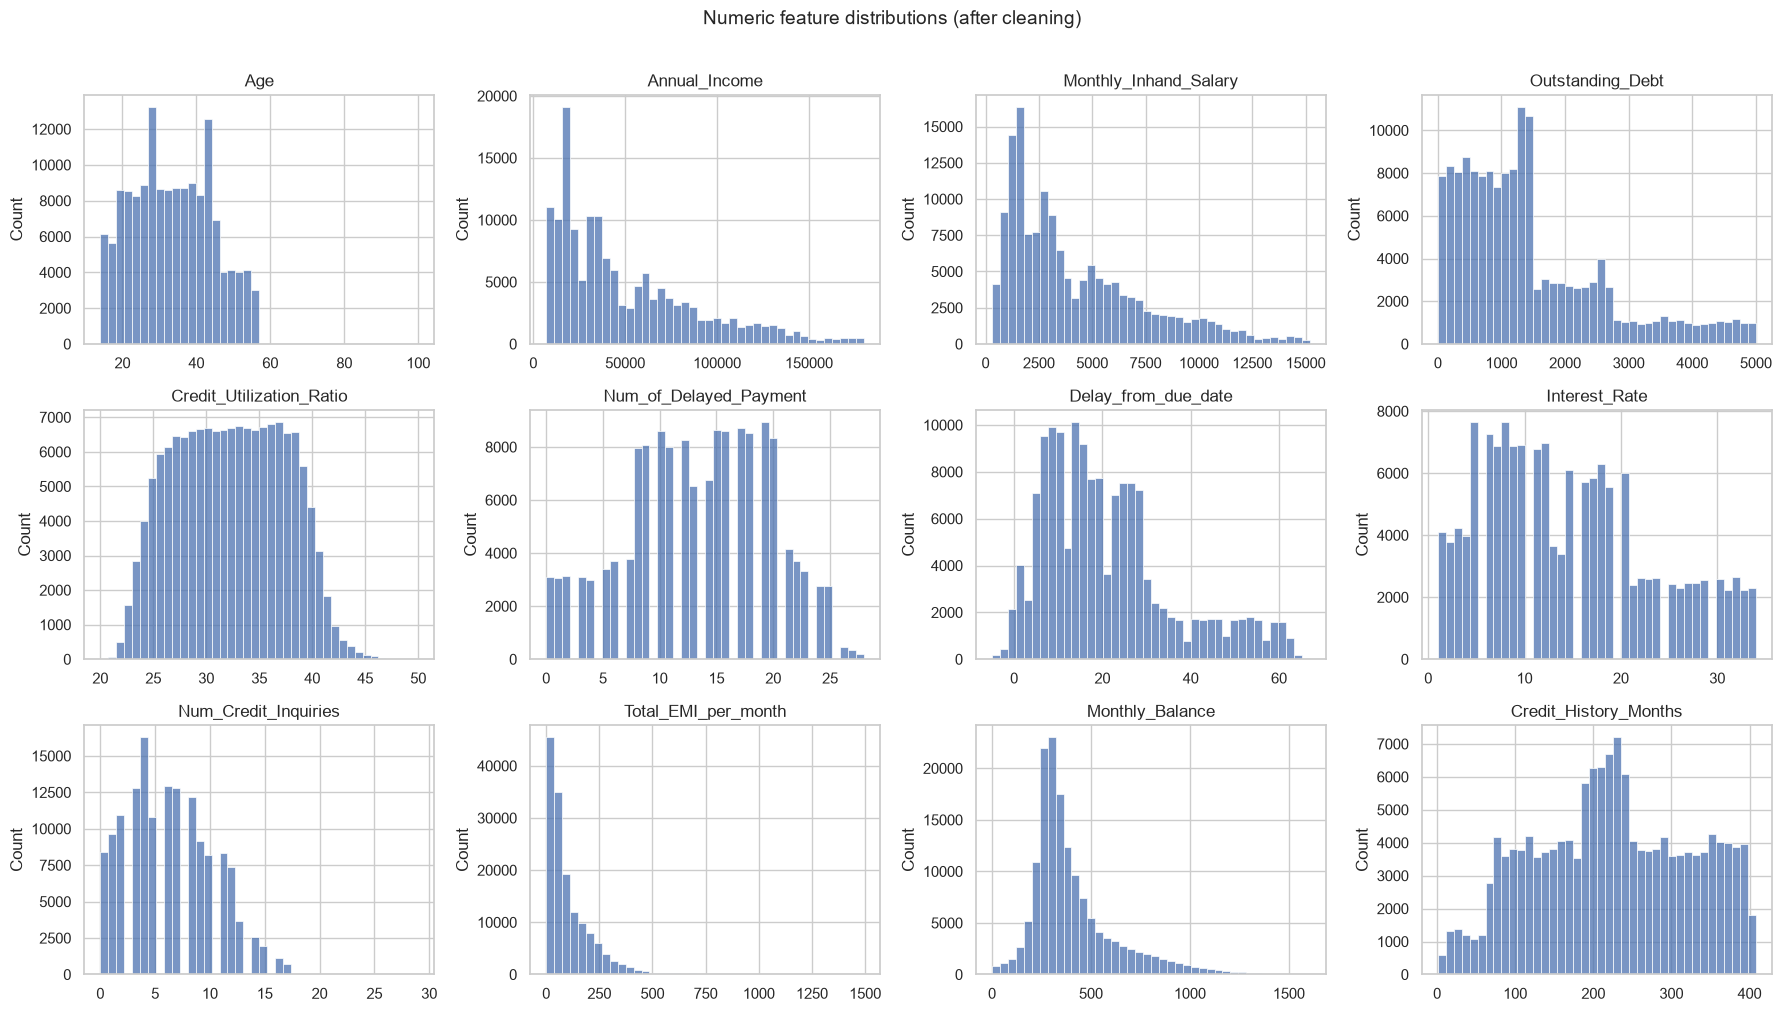

In [ ]:
plot_numeric_distributions(clean)

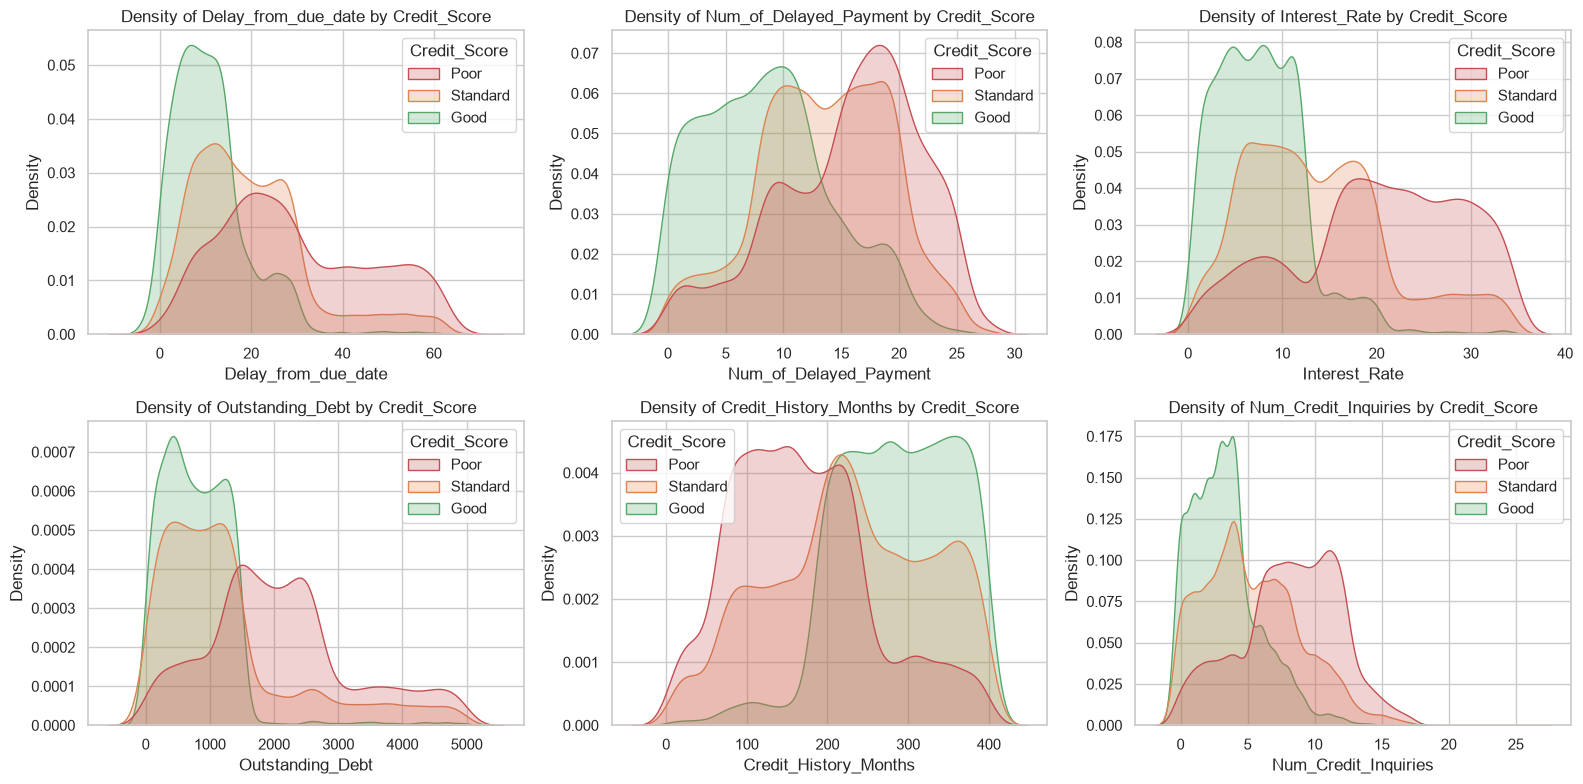

Median by class (quick read of the density plots):


,Delay_from_due_date,Num_of_Delayed_Payment,Interest_Rate,Outstanding_Debt,Credit_History_Months,Num_Credit_Inquiries
Credit_Score,,,,,,
Poor,27.0,17.0,21.0,1945.35,161.0,8.0
Standard,18.0,14.0,13.0,1001.61,227.0,5.0
Good,10.0,8.0,7.0,736.47,288.0,3.0


In [ ]:
plot_density(clean[clean._is_train == 1])

d = clean[clean._is_train == 1]
print("Median by class (quick read of the density plots):")
display(d.groupby(TARGET)[["Delay_from_due_date", "Num_of_Delayed_Payment", "Interest_Rate",
                           "Outstanding_Debt", "Credit_History_Months", "Num_Credit_Inquiries"]].median().loc[CLASSES])

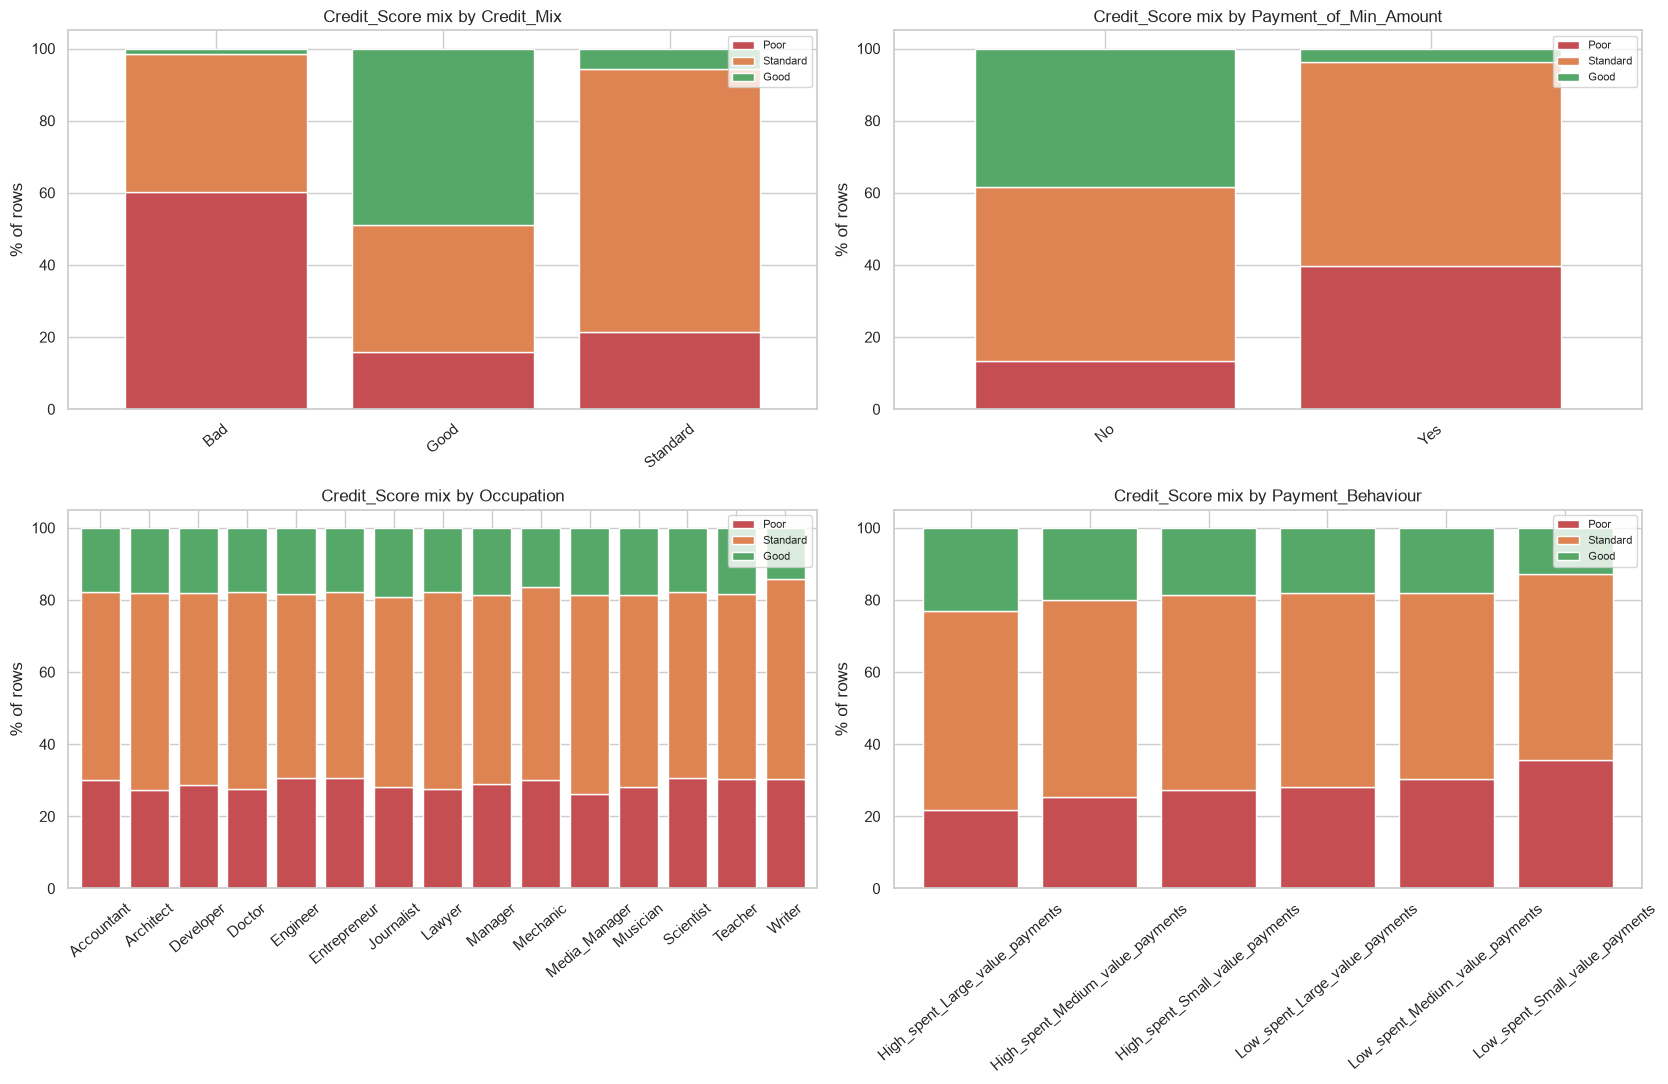

In [ ]:
plot_pct_stacked(clean[clean._is_train == 1])

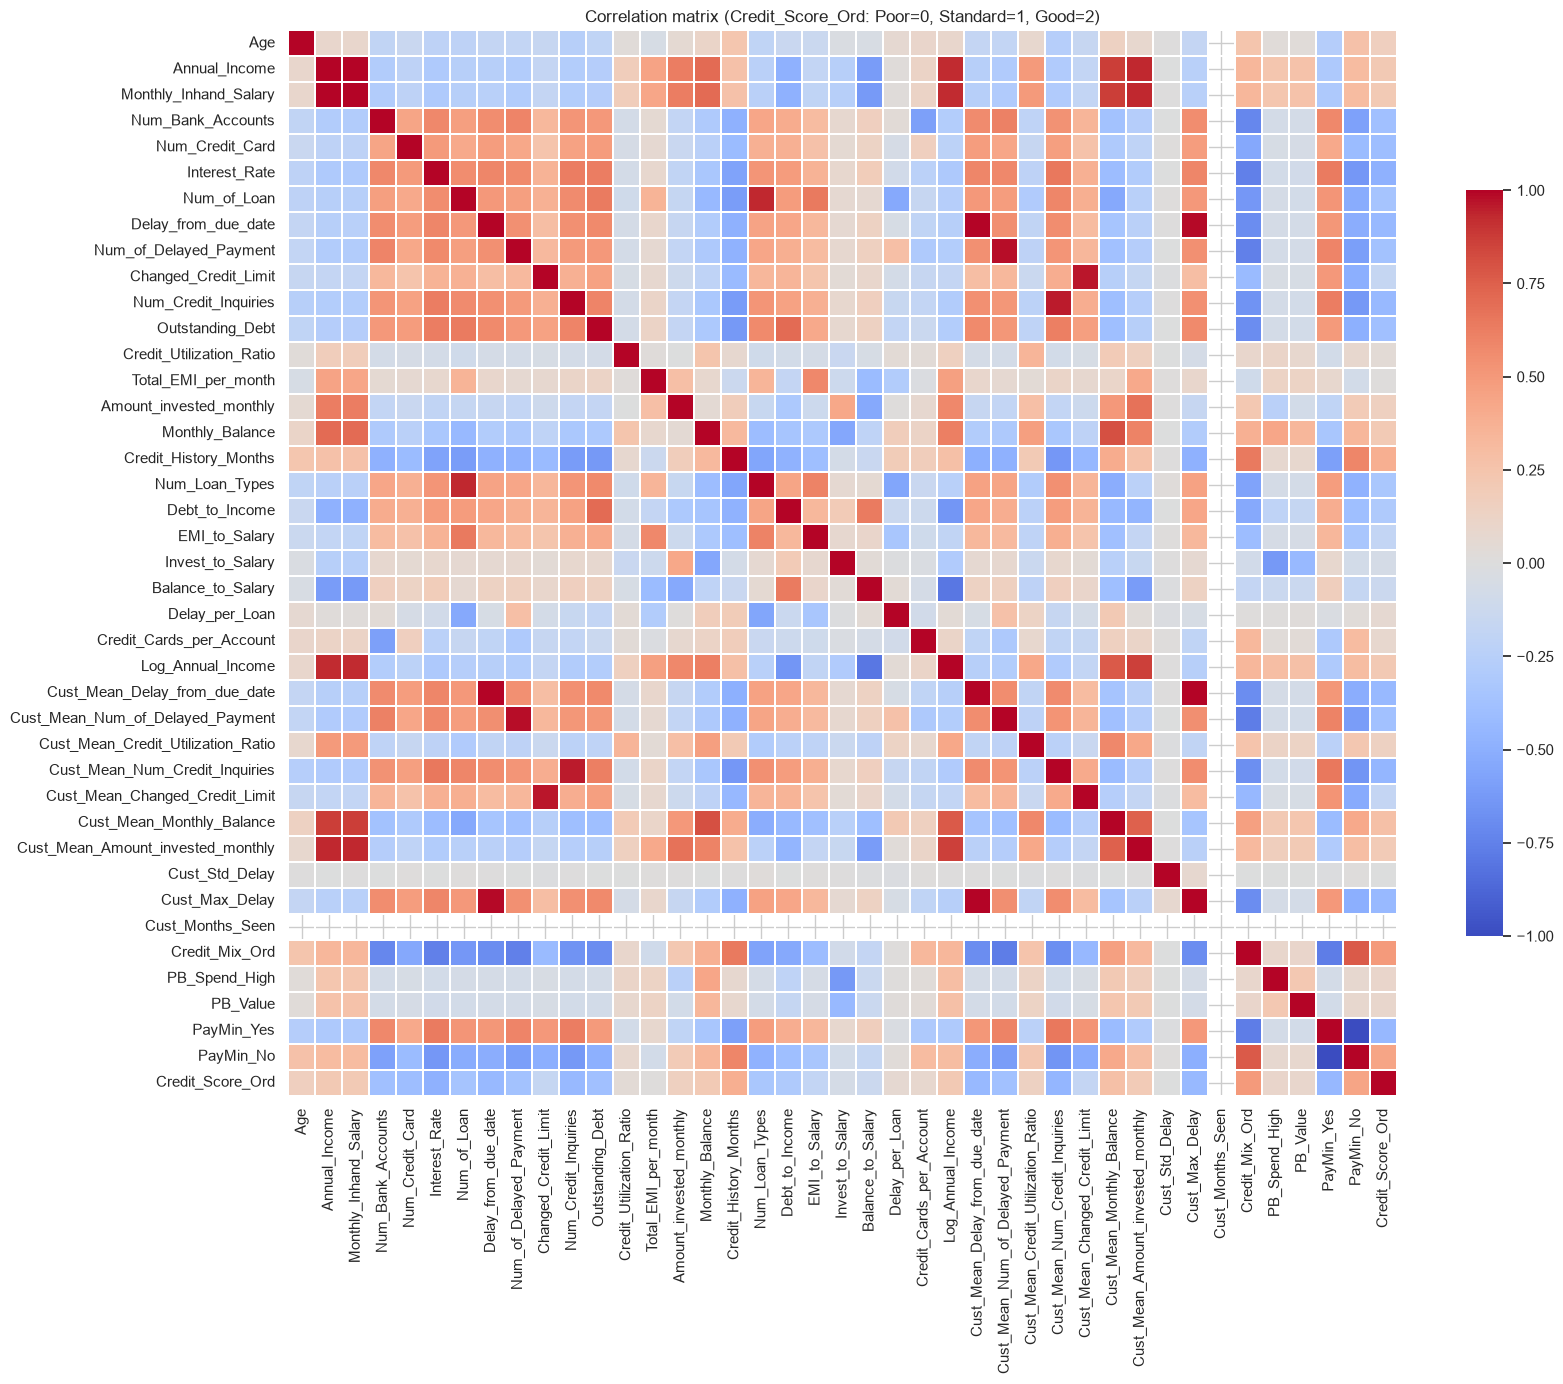

In [ ]:
plot_corr(tr, y_all)

In [ ]:

groups = tr["Customer_ID"].values
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf.split(tr, y_all, groups))
assert not set(groups[tr_idx]) & set(groups[va_idx]), "customer leakage between train and validation!"

tr_df, va_df = tr.iloc[tr_idx].reset_index(drop=True), tr.iloc[va_idx].reset_index(drop=True)
y_tr, y_va, g_tr = y_all[tr_idx], y_all[va_idx], groups[tr_idx]

display(pd.DataFrame({
    "Rows": [len(tr_idx), len(va_idx)],
    "Share": [f"{len(tr_idx)/len(tr):.0%}", f"{len(va_idx)/len(tr):.0%}"],
    "Customers": [len(set(groups[tr_idx])), len(set(groups[va_idx]))],
    "Poor %": [(y_tr == 0).mean() * 100, (y_va == 0).mean() * 100],
    "Standard %": [(y_tr == 1).mean() * 100, (y_va == 1).mean() * 100],
    "Good %": [(y_tr == 2).mean() * 100, (y_va == 2).mean() * 100],
}, index=["Train", "Validation"]).round(2))

,Rows,Share,Customers,Poor %,Standard %,Good %
Train,80000,80%,10000,29.00,53.17,17.83
Validation,20000,20%,2500,28.99,53.18,17.84


In [ ]:

TE_COLS = ["Occupation", "Payment_Behaviour"]

def _te_fit(cat, y, m=30):
    prior = np.bincount(y, minlength=3) / len(y)
    tab = pd.crosstab(cat, y).reindex(columns=[0, 1, 2], fill_value=0)
    n = tab.sum(axis=1).values[:, None]
    enc = (tab.values + m * prior) / (n + m)
    return pd.DataFrame(enc, index=tab.index, columns=range(3)), prior

def _te_apply(cat, mapping, prior):
    out = mapping.reindex(cat.values)
    return out.fillna(dict(enumerate(prior))).values

def target_encode(train_df, y_train, groups, others):
    """OOF (group-wise) encoding for the training rows - so a row never sees its own label -
    full-train mapping for every other frame."""
    tr = np.zeros((len(train_df), 0)); names = []
    te_tr = {}; te_other = [dict() for _ in others]
    for col in TE_COLS:
        arr = np.zeros((len(train_df), 3))
        sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
        for a, b in sgkf.split(train_df, y_train, groups):
            mp, pr = _te_fit(train_df[col].iloc[a], y_train[a])
            arr[b] = _te_apply(train_df[col].iloc[b], mp, pr)
        mp, pr = _te_fit(train_df[col], y_train)
        for k in range(3):
            nm = f"TE_{col}_{CLASSES[k]}"
            te_tr[nm] = arr[:, k]
            for j, o in enumerate(others):
                te_other[j][nm] = _te_apply(o[col], mp, pr)[:, k]
    return pd.DataFrame(te_tr, index=train_df.index), [pd.DataFrame(d, index=o.index) for d, o in zip(te_other, others)]

def make_matrices(tr_df, y_tr, g_tr, others, use_smote):
    """target-encode -> scale -> (SMOTE). Returns scaled arrays + fitted objects."""
    te_tr, te_oth = target_encode(tr_df, y_tr, g_tr, others)
    base_cols = [c for c in tr_df.columns if c not in DROP_FOR_MODEL]
    X_tr = pd.concat([tr_df[base_cols], te_tr], axis=1)
    X_oth = [pd.concat([o[base_cols], t], axis=1) for o, t in zip(others, te_oth)]
    feat_names = X_tr.columns.tolist()
    scaler = StandardScaler().fit(X_tr)
    Xs_tr = scaler.transform(X_tr)
    Xs_oth = [scaler.transform(x) for x in X_oth]
    X_fit, y_fit = Xs_tr, y_tr
    if use_smote:
        X_fit, y_fit = SMOTE(random_state=SEED, k_neighbors=5).fit_resample(Xs_tr, y_tr)
    return X_fit, y_fit, Xs_tr, Xs_oth, feat_names, scaler
prepared = {}
for strat in ["ClassWeight", "SMOTE"]:
    X_fit, y_fit, Xs_tr, (Xs_va,), names, scaler = make_matrices(tr_df, y_tr, g_tr, [va_df], strat == "SMOTE")
    prepared[strat] = dict(X_fit=X_fit, y_fit=y_fit, Xs_tr=Xs_tr, Xs_va=Xs_va, names=names)
    print(f"{strat:12} -> fit rows: {len(y_fit):>6} | class counts {np.bincount(y_fit).tolist()} | features: {len(names)}")

ClassWeight  -> fit rows:  80000 | class counts [23200, 42539, 14261] | features: 55
SMOTE        -> fit rows: 127617 | class counts [42539, 42539, 42539] | features: 55


In [ ]:
def get_models(class_weight):
    cw = "balanced" if class_weight else None
    return {
        "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=18, min_samples_leaf=3, n_jobs=-1,
                                                 class_weight=cw, random_state=SEED),
        "XGBoost": XGBClassifier(n_estimators=350, max_depth=7, learning_rate=0.08, subsample=0.85,
                                 colsample_bytree=0.8, objective="multi:softprob", tree_method="hist",
                                 n_jobs=-1, random_state=SEED, verbosity=0),
        "LightGBM": LGBMClassifier(n_estimators=400, learning_rate=0.07, num_leaves=63, subsample=0.85,
                                   subsample_freq=1, colsample_bytree=0.8, class_weight=cw, n_jobs=-1,
                                   random_state=SEED, verbose=-1),
        "Logistic Regression": LogisticRegression(max_iter=2000, C=1.0, class_weight=cw, n_jobs=-1),
    }

def fit_model(model, name, X, y, class_weight):
    if name == "XGBoost" and class_weight:
        model.fit(X, y, sample_weight=compute_sample_weight("balanced", y))
    else:
        model.fit(X, y)
    return model

def metrics(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
            "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
            "F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
            "Macro_F1": f1_score(y_true, y_pred, average="macro"),
            "Weighted_F1": f1_score(y_true, y_pred, average="weighted")}

results, fitted, reports, preds = [], {}, {}, {}
for strat in ["ClassWeight", "SMOTE"]:
    P = prepared[strat]
    for name, model in get_models(class_weight=strat == "ClassWeight").items():
        t = time.time()
        fit_model(model, name, P["X_fit"], P["y_fit"], class_weight=strat == "ClassWeight")
        p_tr, p_va = model.predict(P["Xs_tr"]), model.predict(P["Xs_va"])
        m_va, m_tr = metrics(y_va, p_va), metrics(y_tr, p_tr)
        results.append({"Model": name, "Imbalance": strat, **m_va,
                        "Train_Macro_F1": m_tr["Macro_F1"],
                        "Train_Val_F1_Gap": m_tr["Macro_F1"] - m_va["Macro_F1"]})
        fitted[(name, strat)], preds[(name, strat)] = model, p_va
        reports[(name, strat)] = classification_report(y_va, p_va, target_names=CLASSES, digits=4)
        print(f"{name:20} [{strat:11}] Val Acc: {m_va['Accuracy']:.4f} | Val Macro F1: {m_va['Macro_F1']:.4f} "
              f"| Gap: {results[-1]['Train_Val_F1_Gap']:.4f}  ({time.time()-t:.0f}s)")

Random Forest        [ClassWeight] Val Acc: 0.6975 | Val Macro F1: 0.6901 | Gap: 0.1395  (36s)
XGBoost              [ClassWeight] Val Acc: 0.6950 | Val Macro F1: 0.6843 | Gap: 0.1837  (37s)
LightGBM             [ClassWeight] Val Acc: 0.6996 | Val Macro F1: 0.6874 | Gap: 0.1983  (48s)
Logistic Regression  [ClassWeight] Val Acc: 0.6638 | Val Macro F1: 0.6565 | Gap: -0.0002  (6s)
Random Forest        [SMOTE      ] Val Acc: 0.6983 | Val Macro F1: 0.6898 | Gap: 0.1461  (110s)
XGBoost              [SMOTE      ] Val Acc: 0.6925 | Val Macro F1: 0.6829 | Gap: 0.1875  (91s)
LightGBM             [SMOTE      ] Val Acc: 0.6957 | Val Macro F1: 0.6848 | Gap: 0.2058  (66s)
Logistic Regression  [SMOTE      ] Val Acc: 0.6629 | Val Macro F1: 0.6555 | Gap: 0.0007  (14s)


,Model,Imbalance,Accuracy,Precision,Recall,F1,Macro_F1,Weighted_F1,Train_Macro_F1,Train_Val_F1_Gap
0,Random Forest,ClassWeight,0.6974,0.7328,0.6974,0.7012,0.6901,0.7012,0.8296,0.1395
1,Random Forest,SMOTE,0.6982,0.7292,0.6982,0.7022,0.6898,0.7022,0.8359,0.1461
2,LightGBM,ClassWeight,0.6996,0.7174,0.6996,0.7030,0.6874,0.7030,0.8857,0.1983
3,LightGBM,SMOTE,0.6958,0.7141,0.6958,0.6988,0.6848,0.6988,0.8906,0.2058
4,XGBoost,ClassWeight,0.6950,0.7165,0.6950,0.6985,0.6843,0.6985,0.8679,0.1837
5,XGBoost,SMOTE,0.6926,0.7141,0.6926,0.6956,0.6829,0.6956,0.8704,0.1875
6,Logistic Regression,ClassWeight,0.6638,0.7083,0.6638,0.6683,0.6565,0.6683,0.6563,-0.0002
7,Logistic Regression,SMOTE,0.6629,0.7057,0.6629,0.6672,0.6555,0.6672,0.6563,0.0007


Winner chosen on Validation Macro F1: Random Forest with ClassWeight (Macro F1 = 0.6901, gap = 0.1395)


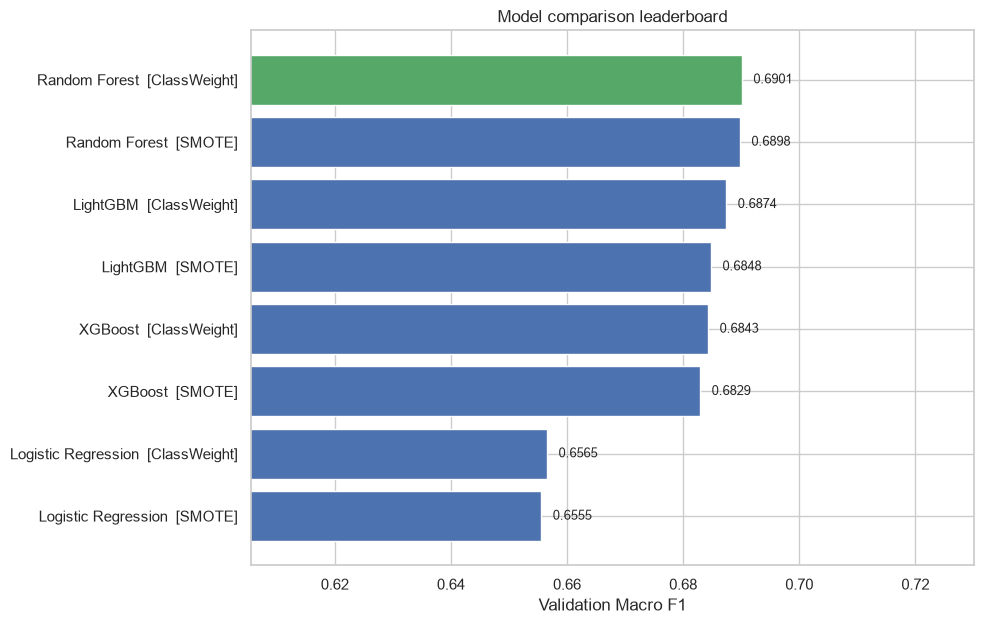

In [ ]:
leaderboard = pd.DataFrame(results).sort_values("Macro_F1", ascending=False).reset_index(drop=True)
display(leaderboard.round(4))
leaderboard.to_csv(f"{OUT}/model_leaderboard.csv", index=False)

best = leaderboard.iloc[0]
best_key = (best.Model, best.Imbalance)
print(f"Winner chosen on Validation Macro F1: {best.Model} with {best.Imbalance} (Macro F1 = {best.Macro_F1:.4f}, "
      f"gap = {best.Train_Val_F1_Gap:.4f})")

def plot_leaderboard(lb):
    d = lb.sort_values("Macro_F1")
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(d) + 2))
    colors = ["#55A868" if i == len(d) - 1 else "#4C72B0" for i in range(len(d))]
    ax.barh(d["Model"] + "  [" + d["Imbalance"] + "]", d["Macro_F1"], color=colors)
    for i, v in enumerate(d["Macro_F1"]):
        ax.text(v + 0.002, i, f"{v:.4f}", va="center", fontsize=9)
    ax.set_xlim(d["Macro_F1"].min() - 0.05, min(1, d["Macro_F1"].max() + 0.04))
    ax.set_xlabel("Validation Macro F1"); ax.set_title("Model comparison leaderboard")
    savefig("05_model_leaderboard.png")

plot_leaderboard(leaderboard)

Classification report - Random Forest [ClassWeight] (validation)
              precision    recall  f1-score   support

        Poor     0.6800    0.7378    0.7078      5798
    Standard     0.8305    0.6290    0.7158     10635
        Good     0.5273    0.8360    0.6467      3567

    accuracy                         0.6975     20000
   macro avg     0.6793    0.7343    0.6901     20000
weighted avg     0.7328    0.6975    0.7012     20000



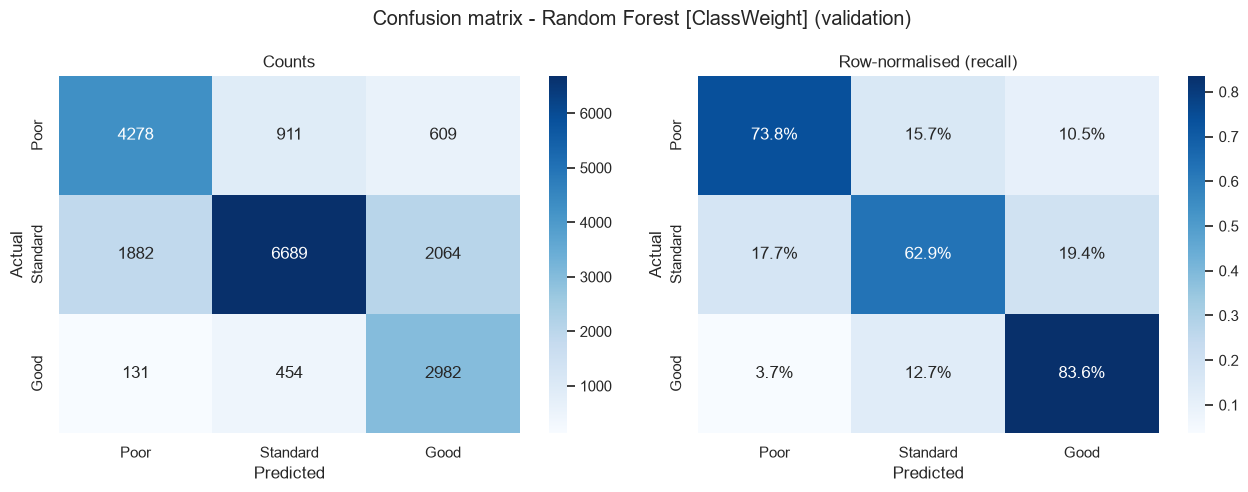

,Train (actual),Val (actual),Val (predicted)
Poor,29.00,28.99,31.46
Standard,53.17,53.18,40.27
Good,17.83,17.84,28.28


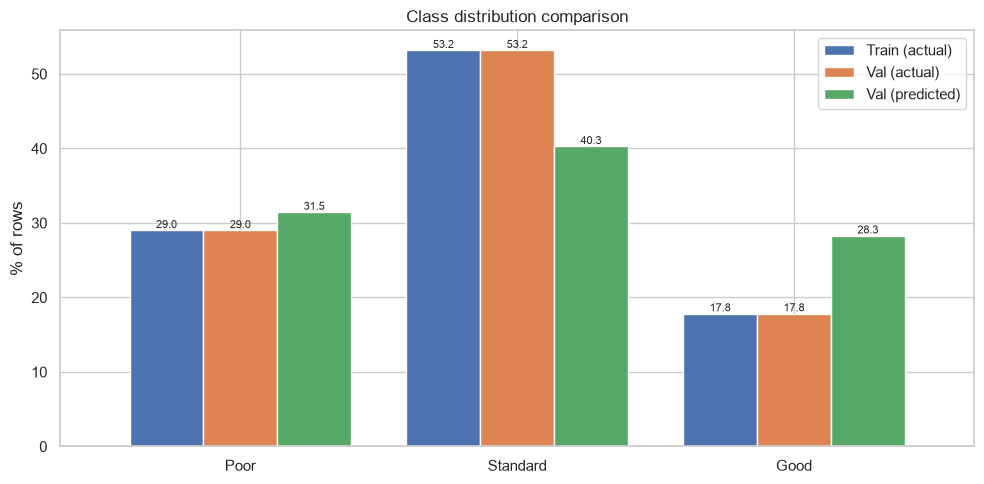

Takeaways - Confusion matrix:
- Poor: recall 73.8%; most often mistaken for 'Standard' (911 rows)
- Standard: recall 62.9%; most often mistaken for 'Good' (2064 rows)
- Good: recall 83.6%; most often mistaken for 'Standard' (454 rows)


In [ ]:
print(f"Classification report - {best_key[0]} [{best_key[1]}] (validation)")
print(reports[best_key])

def plot_confusion(y_true, y_pred, title, fname):
    cm = confusion_matrix(y_true, y_pred)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
    axes[0].set_title("Counts");
    sns.heatmap(cmn, annot=True, fmt=".1%", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
    axes[1].set_title("Row-normalised (recall)")
    for a in axes: a.set_xlabel("Predicted"); a.set_ylabel("Actual")
    fig.suptitle(title); savefig(fname)

def plot_class_distribution(dist_df, fname, title):
    ax = dist_df.plot(kind="bar", figsize=(10, 5), width=0.8, color=["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"][:dist_df.shape[1]])
    ax.set_ylabel("% of rows"); ax.set_title(title); ax.tick_params(axis="x", rotation=0)
    for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=8)
    savefig(fname)

plot_confusion(y_va, preds[best_key], f"Confusion matrix - {best_key[0]} [{best_key[1]}] (validation)", "cm")

class_dist = pd.DataFrame({
    "Train (actual)": np.bincount(y_tr, minlength=3) / len(y_tr),
    "Val (actual)": np.bincount(y_va, minlength=3) / len(y_va),
    "Val (predicted)": np.bincount(preds[best_key], minlength=3) / len(y_va)}, index=CLASSES) * 100
if best_key[1] == "SMOTE":
    class_dist["Train after SMOTE"] = 100 / 3
display(class_dist.round(2))
plot_class_distribution(class_dist, "dist", "Class distribution comparison")

cm = confusion_matrix(y_va, preds[best_key])
print("Takeaways - Confusion matrix:")
for k, c in enumerate(CLASSES):
    wrong = {CLASSES[j]: cm[k, j] for j in range(3) if j != k}
    worst = max(wrong, key=wrong.get)
    print(f"- {c}: recall {cm[k, k] / cm[k].sum():.1%}; most often mistaken for '{worst}' ({wrong[worst]} rows)")

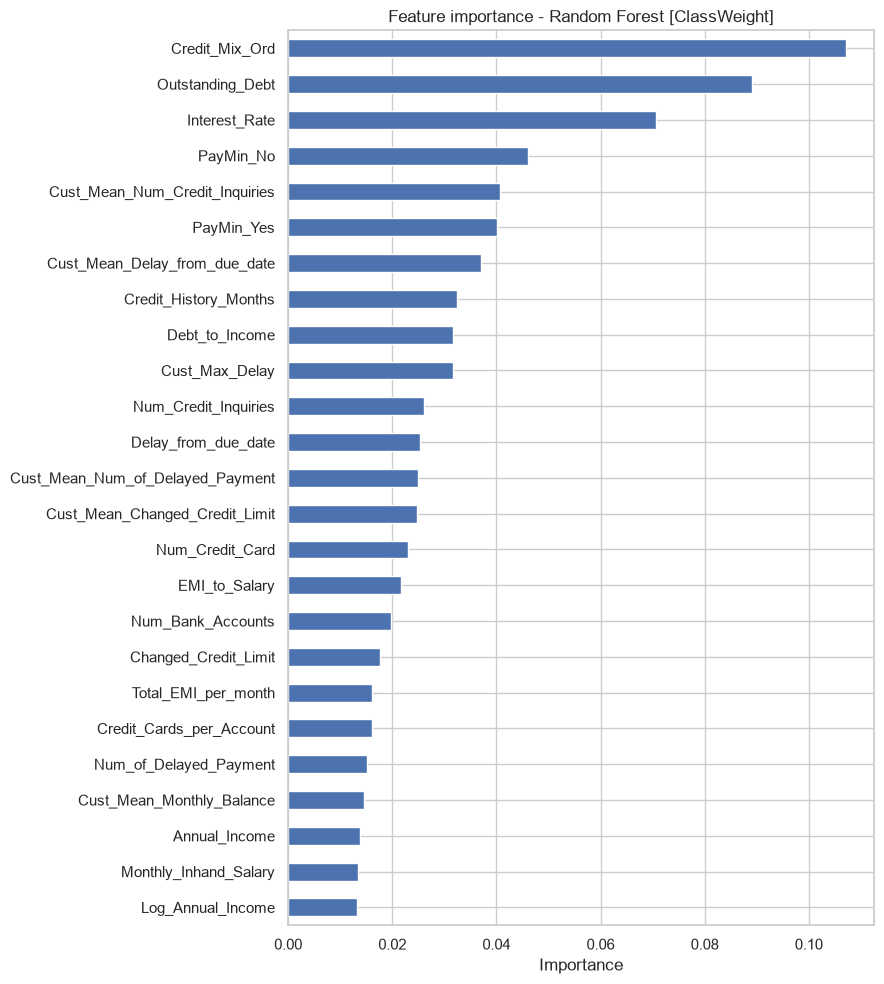

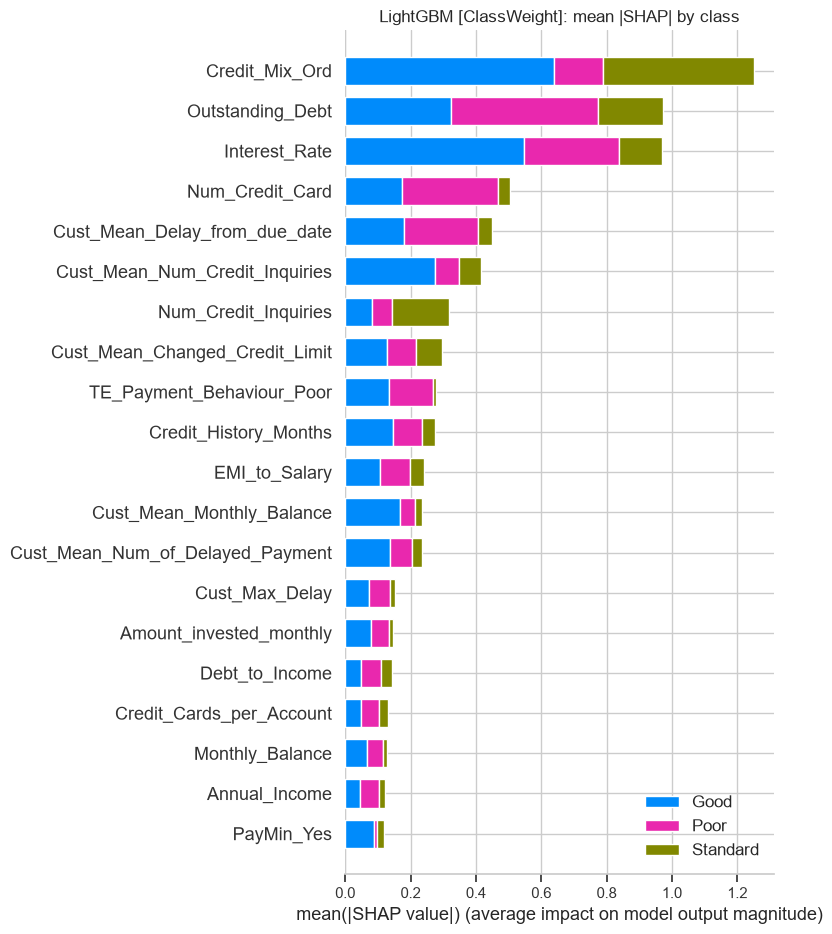

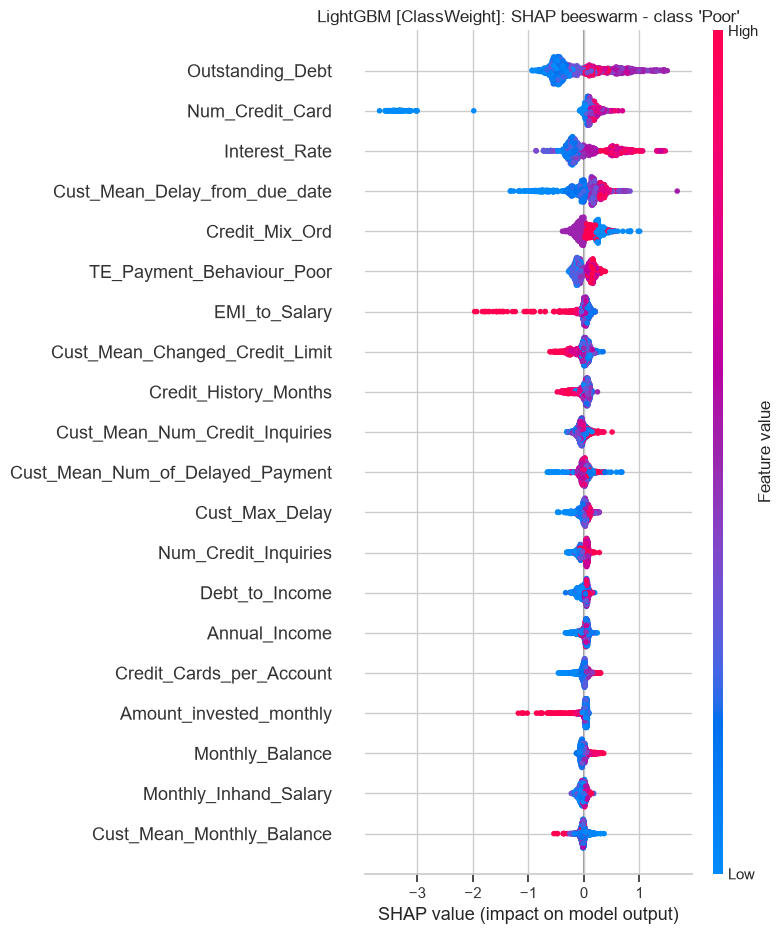

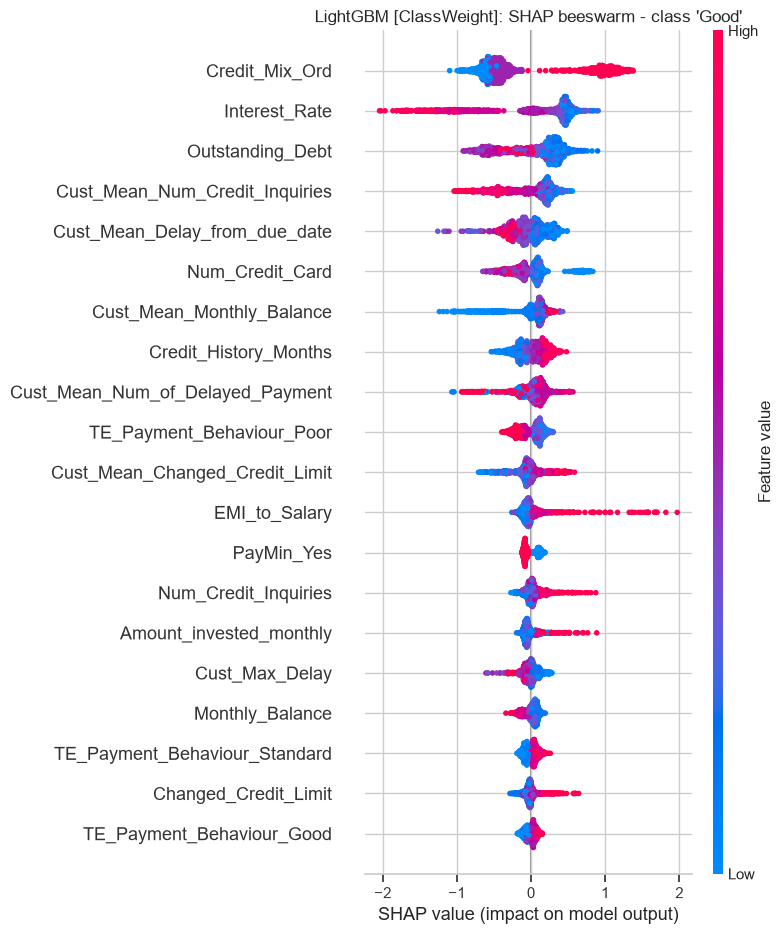

In [ ]:
def plot_feature_importance(model, names, title, fname, top=25):
    imp = getattr(model, "feature_importances_", None)
    if imp is None:
        imp = np.abs(model.coef_).mean(axis=0)
    s = pd.Series(imp, index=names).sort_values().tail(top)
    plt.figure(figsize=(9, 0.32 * len(s) + 2))
    s.plot(kind="barh", color="#4C72B0"); plt.title(title); plt.xlabel("Importance")
    savefig(fname)

def plot_shap(model, X, names, title_prefix):
    import shap
    idx = np.random.RandomState(SEED).choice(len(X), min(1500, len(X)), replace=False)
    Xs = pd.DataFrame(X[idx], columns=names)
    sv = shap.TreeExplainer(model).shap_values(Xs)
    sv = [sv[:, :, k] for k in range(sv.shape[2])] if isinstance(sv, np.ndarray) and sv.ndim == 3 else list(sv)
    plt.figure(); shap.summary_plot(sv, Xs, plot_type="bar", class_names=CLASSES, max_display=20, show=False)
    plt.title(f"{title_prefix}: mean |SHAP| by class"); savefig("08a_shap_bar.png")
    plt.figure(); shap.summary_plot(sv[0], Xs, max_display=20, show=False)
    plt.title(f"{title_prefix}: SHAP beeswarm - class 'Poor'"); savefig("08b_shap_beeswarm_poor.png")
    plt.figure(); shap.summary_plot(sv[2], Xs, max_display=20, show=False)
    plt.title(f"{title_prefix}: SHAP beeswarm - class 'Good'"); savefig("08c_shap_beeswarm_good.png")

tree_row = leaderboard[leaderboard.Model != "Logistic Regression"].iloc[0]
tkey = (tree_row.Model, tree_row.Imbalance)
plot_feature_importance(fitted[tkey], prepared[tkey[1]]["names"], f"Feature importance - {tkey[0]} [{tkey[1]}]", "fi")

boost_row = leaderboard[leaderboard.Model.isin(["XGBoost", "LightGBM"])].iloc[0]
bkey = (boost_row.Model, boost_row.Imbalance)
plot_shap(fitted[bkey], prepared[bkey[1]]["Xs_va"], prepared[bkey[1]]["names"], f"{bkey[0]} [{bkey[1]}]")

In [ ]:
use_smote = best_key[1] == "SMOTE"
X_fit, y_fit, Xs_full, (Xs_te,), names, final_scaler = make_matrices(tr.reset_index(drop=True), y_all, groups,
                                                           [te.reset_index(drop=True)], use_smote)
final_model = get_models(class_weight=not use_smote)[best_key[0]]
fit_model(final_model, best_key[0], X_fit, y_fit, class_weight=not use_smote)
print(f"Final model: {best_key[0]} [{best_key[1]}] trained on {len(y_fit)} rows, {len(names)} features")

proba = final_model.predict_proba(Xs_te)
pred = proba.argmax(axis=1)

submission_full = pd.DataFrame({"ID": te["_row_id"].values, "Customer_ID": te["Customer_ID"].values,
                                "Month": te["Month"].values, "Credit_Score": [CLASSES[i] for i in pred]})
for k, c in enumerate(CLASSES):
    submission_full[f"Prob_{c}"] = proba[:, k].round(4)

submission_full.to_csv(f"{OUT}/test_predictions.csv", index=False)
submission_full[["ID", "Credit_Score"]].to_csv(f"{OUT}/submission.csv", index=False)
print(f"Saved {len(submission_full)} test predictions (test rows: {len(test)}) to ./{OUT}/")
display(submission_full.head())

Final model: Random Forest [ClassWeight] trained on 100000 rows, 55 features
Saved 50000 test predictions (test rows: 50000) to ./outputs/


,ID,Customer_ID,Month,Credit_Score,Prob_Poor,Prob_Standard,Prob_Good
0,0x16292,CUS_0x1000,September,Poor,0.8722,0.1275,0.0003
1,0x16293,CUS_0x1000,October,Poor,0.9013,0.0985,0.0002
2,0x16294,CUS_0x1000,November,Poor,0.8837,0.1161,0.0002
3,0x16295,CUS_0x1000,December,Poor,0.8799,0.1197,0.0003
4,0x66aa,CUS_0x1009,September,Standard,0.0348,0.8934,0.0718


In [ ]:
# ---- Save the trained model as a .pkl bundle ----
# Needs `final_scaler` (set in the cell above), so run that cell first.
import pickle

te_maps = {}
for col in TE_COLS:
    te_maps[col] = _te_fit(tr[col], y_all)        # same full-train mapping used during training

base_cols = [c for c in tr.columns if c not in DROP_FOR_MODEL]
bundle = {
    "model": final_model,
    "model_name": best_key[0],
    "imbalance_strategy": best_key[1],
    "scaler": final_scaler,
    "feature_names": names,
    "base_cols": base_cols,
    "te_cols": TE_COLS,
    "te_maps": te_maps,
    "classes": CLASSES,
    "drop_for_model": DROP_FOR_MODEL,
}
with open("credit_score_model.pkl", "wb") as fh:
    pickle.dump(bundle, fh, protocol=5)
print("Saved credit_score_model.pkl ->", round(os.path.getsize("credit_score_model.pkl") / 1e6, 1), "MB")

# Sanity check: rebuild the test matrix from the bundle only and compare with the notebook's probabilities
te_r = te.reset_index(drop=True)
chk = te_r[base_cols].copy()
for col in TE_COLS:
    mp, pr = te_maps[col]
    enc = _te_apply(te_r[col], mp, pr)
    for k in range(3):
        chk[f"TE_{col}_{CLASSES[k]}"] = enc[:, k]
chk = chk[names]
diff = np.abs(final_model.predict_proba(final_scaler.transform(chk)) - proba).max()
print("Max difference vs notebook predictions:", float(diff))


Saved credit_score_model.pkl -> 148.1 MB
Max difference vs notebook predictions: 4.440892098500626e-16


,Train labels,Test predictions
Poor,29.00,32.08
Standard,53.17,39.99
Good,17.83,27.93


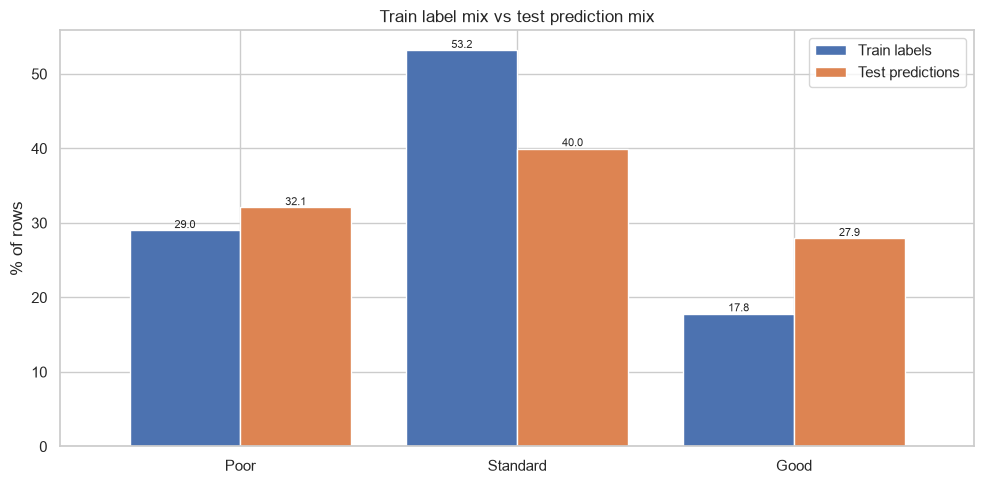

Mean prediction confidence per predicted class:


,Confidence
Poor,0.770
Standard,0.736
Good,0.710


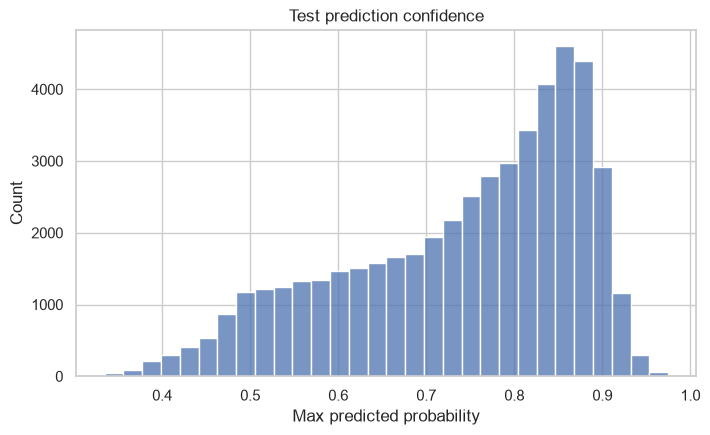

Predicted mix by test month (%):


Credit_Score,Poor,Standard,Good
Month,,,
September,32.2,39.9,27.9
October,32.0,40.1,27.9
November,32.0,40.0,27.9
December,32.1,39.9,28.0


Takeaway - predicted mix vs training labels (percentage points): {'Poor': 3.1, 'Standard': -13.2, 'Good': 10.1}
Balanced class weights / SMOTE push predictions away from the majority class ('Standard'), which is why test predictions under-represent it relative to the training labels.


In [ ]:
pred_dist = pd.DataFrame({"Train labels": np.bincount(y_all, minlength=3) / len(y_all),
                          "Test predictions": np.bincount(pred, minlength=3) / len(pred)}, index=CLASSES) * 100
display(pred_dist.round(2))
plot_class_distribution(pred_dist, "pred", "Train label mix vs test prediction mix")

conf = pd.Series(proba.max(axis=1)).groupby(pred).mean().rename(dict(enumerate(CLASSES))).round(3)
print("Mean prediction confidence per predicted class:")
display(conf.to_frame("Confidence"))

plt.figure(figsize=(8, 4.5))
sns.histplot(proba.max(axis=1), bins=30, color="#4C72B0")
plt.xlabel("Max predicted probability"); plt.title("Test prediction confidence")
plt.show()

by_month = pd.crosstab(submission_full["Month"], submission_full["Credit_Score"], normalize="index").reindex(MONTHS[8:])[CLASSES] * 100
print("Predicted mix by test month (%):")
display(by_month.round(1))

shift = (pred_dist["Test predictions"] - pred_dist["Train labels"]).round(1)
print(f"Takeaway - predicted mix vs training labels (percentage points): {shift.to_dict()}")
print("Balanced class weights / SMOTE push predictions away from the majority class ('Standard'), "
      "which is why test predictions under-represent it relative to the training labels.")